Import and set up data

In [2]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

df = pd.read_csv("../Data/transformed_study_data.csv")

Implement the initial visualization

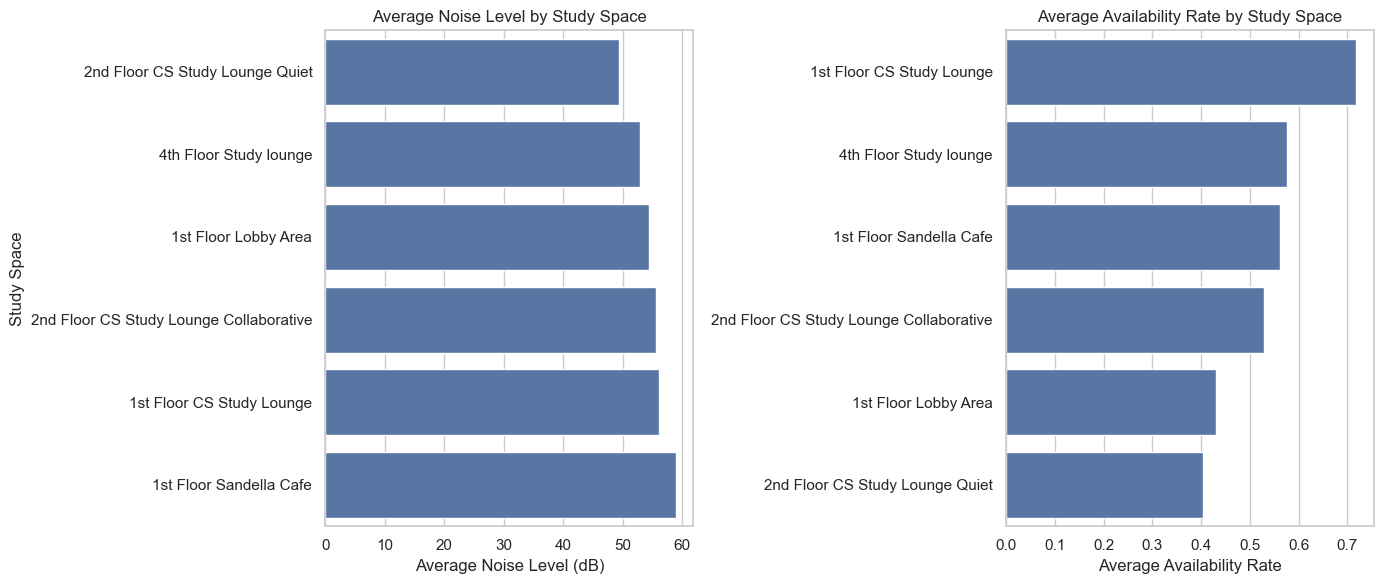

In [3]:
# Convert date back to datetime
df["date"] = pd.to_datetime(df["date"])

# Aggregate data by location
comparison_data = (
    df.groupby("location")[["noise_level", "availability_rate"]]
      .mean()
      .reset_index()
)

# Set study space order
location_order = [
    "1st Floor Sandella Cafe",
    "1st Floor Lobby Area",
    "1st Floor CS Study Lounge",
    "2nd Floor CS Study Lounge Collaborative",
    "2nd Floor CS Study Lounge Quiet",
    "4th Floor Study lounge"
]

# Create side-by-side ranked bar charts
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 6)
)

# Noise ranking
noise_rank = comparison_data.sort_values(
    by="noise_level",
    ascending=True
)
sns.barplot(
    data=noise_rank,
    x="noise_level",
    y="location",
    ax=axes[0]
)
axes[0].set_title("Average Noise Level by Study Space")
axes[0].set_xlabel("Average Noise Level (dB)")
axes[0].set_ylabel("Study Space")

# Availability ranking 
availability_rank = comparison_data.sort_values(
    by="availability_rate",
    ascending=False
)
sns.barplot(
    data=availability_rank,
    x="availability_rate",
    y="location",
    ax=axes[1]
)
axes[1].set_title("Average Availability Rate by Study Space")
axes[1].set_xlabel("Average Availability Rate")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

Implement interaction and improvements to the original visualization

In [15]:
import plotly.express as px

color_map = {
    "1st Floor Sandella Cafe": "#1f77b4",
    "1st Floor Lobby Area": "#ff7f0e",
    "1st Floor CS Study Lounge": "#2ca02c",
    "2nd Floor CS Study Lounge Collaborative": "#d62728",
    "2nd Floor CS Study Lounge Quiet": "#9467bd",
    "4th Floor Study lounge": "#8c564b"
}

fig_noise = px.bar(
    noise_rank,
    x="noise_level",
    y="location",
    color="location",
    color_discrete_map=color_map,
    orientation="h",
    custom_data=["location", "noise_level"]
)

fig_noise.update_traces(
    hovertemplate=
    "<b>%{customdata[0]}</b><br><br>"
    "Average Noise Level: %{customdata[1]:.2f} dB"
    "<extra></extra>"
)

fig_noise.update_layout(
    title="Average Noise Level by Study Space",
    xaxis_title="Average Noise Level (dB)",
    yaxis_title="Study Space",
    legend_title_text="Location",
    width=700,
    height=300
)

fig_noise.update_yaxes(showticklabels=False)

fig_noise.show()

fig_availability = px.bar(
    availability_rank,
    x="availability_rate",
    y="location",
    color="location",
    color_discrete_map=color_map,
    orientation="h",
    custom_data=["location", "availability_rate"]
)

fig_availability.update_traces(
    hovertemplate=
    "<b>%{customdata[0]}</b><br><br>"
    "Average Availability Rate: %{customdata[1]:.1%}"
    "<extra></extra>"
)

fig_availability.update_layout(
    title="Average Availability Rate by Study Space",
    xaxis_title="Average Availability Rate",
    yaxis_title="Study Space",
    legend_title_text="Location",
    width=700,
    height=300
)

fig_availability.update_yaxes(showticklabels=False)

fig_availability.update_xaxes(tickformat=".0%")

fig_availability.show()